# IMPORT

In [1]:
# In una cella all'inizio del notebook:
# %matplotlib ipympl
# oppure
%matplotlib widget

import matplotlib.pyplot as plt
from matplotlib import rcParams
import pandas as pd
import numpy as np
import re
import os
from scipy.signal import savgol_filter

# FUNCTIONS

In [2]:
def read_current_voltage(file_path, contact_name):
    df = pd.read_csv(file_path)
    current = df[f'{contact_name} Total [A]']
    voltage = df[f'{contact_name} Total [V]']
    time = df['Time[s]']
    std_dev = df[f'stddev({contact_name}) Total [A]']
    return current, voltage, time, std_dev


In [3]:
def read_charge_collection(file_path, contact_name, dt):
    df = pd.read_csv(file_path)
    charge = df[f'{contact_name} ac_carriers [e]']
    time = df['Time[s]']
    # Parametri
    e = 1.602176634e-19  # carica elementare dell'elettrone
    t = time.to_numpy()
    charge = charge.to_numpy()  # carica raccolta per elettroni
    # Calcolo gli indici per gli intervalli
    t_start = t[0]
    t_end = t[-1]
    n_intervals = int((t_end - t_start) / dt)

    currents = []
    times = []
    
    for i in range(n_intervals):
        t1 = t_start + i * dt
        t2 = t_start + (i + 1) * dt
        
        # Trova gli indici più vicini a t1 e t2
        idx1 = np.abs(t - t1).argmin()
        idx2 = np.abs(t - t2).argmin()
        
        if idx1 != idx2:  # evita divisione per zero
            delta_t = t[idx2] - t[idx1]
            delta_q = charge[idx2] - charge[idx1]
            current = (delta_q * e) / delta_t
            currents.append(current)
            times.append(t1 + dt/2)  # punto medio dell'intervallo

    return charge, time, currents, times


In [4]:
def extract_vdc_from_folder(folder_name):
    """
    Estrae la sigla che inizia per 'm' seguita da numeri e opzionalmente 'd' e altri numeri,
    e la converte in valore float con segno negativo.
    Esempi:
        m15d5 -> -15.5
        m21   -> -21.0
    """
    match = re.search(r"m(\d+)(?:d(\d+))?", folder_name)
    if match:
        intero = match.group(1)
        decimale = match.group(2) if match.group(2) else "0"
        vdc = float(f"-{intero}.{decimale}")
        return vdc
    return None

# Current and voltage

## SV Filter parameter

In [5]:
# SV filter parameters
window_length = 501  # Deve essere un numero dispari
polyorder = 3       # Ordine del polinomio

## Import


In [ ]:
# font size
rcParams['font.size'] = 15
# path
# base_path = '/mnt/polmcad/MonteCarlo/DEMC/SPAD_FBK_v2/3D/reduced'
# base_path = '/mnt/csmhome2/lerrico/dev/mcspice/resistor'
base_path = '/mnt/polmcad/MonteCarlo/DEMC/prove'
# base_path = '/mnt/polmcad/MonteCarlo/DEMC/SPAD_FBK_v2/3D'
# folders to plot
bias = np.linspace(-5,5,21)
# bias = [-5.0, -4.47, -3.95, -3.42, -2.89, -2.37, -1.84, -1.32, -0.79, -0.26, 0.26, 0.79, 1.32]
folder_list = [f"IV-{v:.2f}V" for v in bias]
# folder_list = ["1V-100SC-ab"]
#labels
label_list = ["1","2","3","4","5"]

## Graph 
### (Current and voltage, device voltage, external circuit voltage)

In [ ]:
plt.close('all')
plt.figure(figsize=(8,6))
ax1 = plt.gca()
colors = ['r', 'b', 'g']
for idx, (folder_name, leg_label) in enumerate(zip(folder_list, label_list)):
    contact = "ncontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()
    t_mean_limit = 115*1.5e-12
    mask_mean_limit = (t < t_mean_limit) & (t>114*1.5e-12)
    mean_current = np.mean(current_all[mask_mean_limit])
    mask_std = (std_dev <= 2) & (std_dev >= -2)
    # mean_current_svfilter = savgol_filter(current_all, window_length, polyorder)
    ax1.plot(t*1e12, current_all/1e-6, label=f"Vbias = {vdc} V, {leg_label}, Mean (t>{t_mean_limit*1e12} ps) = {mean_current:.2e} A")
    # ax1.plot(t[mask_std]*1e12, mean_current_svfilter[mask_std]/1e-6, label=f"Vbias = {vdc} V, {leg_label}, SV-filtered, window={window_length}, poly={polyorder}", linewidth=2)
ax2 = ax1.twinx()
for folder_name, leg_label in zip(folder_list, label_list):
    contact = "pcontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()
    ax2.plot(t*1e12, voltage, 'r',label=f"Vbias = {vdc} V, {leg_label}")

ax1.set_xlabel('Time (ps)')
ax1.set_ylabel('Current $I_{D}$ ($\mu$A)')
# ax1.set_ylim(-2.5e2, 2.5e2)
# ax1.set_xlim(50, )
# ax1.set_yscale('log')
ax1.set_title('SPAD current')
ax1.grid(True)
ax1.legend(loc='lower left')
ax2.legend(loc='upper right')

ax2.set_ylabel('Voltage (V)')
ax2.legend(loc='upper right')

plt.show()


plt.figure(figsize=(8,6))
for folder_name, leg_label in zip(folder_list, label_list):
    contact = "ncontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()
    plt.plot(t*1e12, voltage, label=f"Vbias = {vdc} V, {leg_label}")
plt.xlabel('Time (ps)')
plt.ylabel('Voltage (V)')
plt.title(f'Quenching voltage, $V_q$')
plt.grid(True)
# plt.xlim(0, 1.5)
# plt.ylim(-17,1)
plt.legend()
plt.show()

plt.figure(figsize=(8,6))
for folder_name, leg_label in zip(folder_list, label_list):
    contact = "ncontact"
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    vdc = extract_vdc_from_folder(folder_name)
    t = time.to_numpy()
    dVq = np.gradient(voltage)
    dt = np.gradient(t)
    plt.plot(t*1e12, vdc-voltage, label=f"{leg_label}")

plt.xlabel('Time (ps)')
plt.ylabel('Voltage (V)')
plt.title(f'SPAD voltage drop, $V_d$')
plt.grid(True)
plt.legend()
plt.show()

# Impact Ionization
## Import

In [ ]:
# font size
rcParams['font.size'] = 15
# path
# base_path = '/mnt/polmcad/MonteCarlo/DEMC/SPAD_FBK_v2/3D'
# folders to plot
folder_list = [f"IV-{v:.2f}V" for v in bias]
# folder_list = ["1V-100SC-ab"]
#labels
label_list = ["1","2","3","4","5"]

## Graph
### Current and impact ionization event binning

In [ ]:
plt.close('all')
plt.figure(figsize=(15,7))
ax1 = plt.gca()
colors = ['r', 'b', 'g']
for idx, folder_name in enumerate(folder_list):
    contact = "ncontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()
    
    ax1.plot(t*1e12, abs(current_all), label=f"$I_D, V_{{bias}}$ = {vdc} V, {label_list[idx]}")

    # --- Istogramma degli eventi di impact ionization su secondo asse y ---
    # Definisci i bin temporali custom   
    t_start = 0
    t_stop = max(t)  # 250 ps
    bins_number = 250
    time_edges = np.linspace(t_start, t_stop, bins_number)
    ion_file = f"{base_path}/{folder_name}/ionization.csv"
    ax2 = ax1.twinx()
    if os.path.exists(ion_file):
        timestamps = pd.read_csv(ion_file, header=None, usecols=[0]).squeeze("columns")
        timestamps = pd.to_numeric(timestamps, errors='coerce')
        timestamps = timestamps.dropna().to_numpy()
        # counts, _ = np.histogram(timestamps, bins=time_edges)

        # Ottieni il prossimo colore dal color cycle

        ax2.hist(timestamps*1e12, bins=time_edges*1e12, edgecolor='k',alpha=0.7,label=f'Impact Ionization events, dt = {(time_edges[1]-time_edges[0])*1e12:.2f} ps, {label_list[idx]}')
    else:
        print(f"File non trovato: {ion_file}")
    ax2.set_ylabel(f'Impact ionization events')
    ax2.set_yscale('log')
    # unisci le legende di ax1 e ax2
    # ax2.set_ylim(0,3e1)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
# ordina/combina come preferisci; qui metto prima ax1 poi ax2
handles = h1 + h2
labels = l1 + l2
leg = ax1.legend(handles, labels, loc='upper right')
leg.get_frame().set_alpha(0.9)

ax1.set_xlabel('Time (ps)')
ax1.set_ylabel('Current (A)')
ax1.set_yscale('log')
ax1.set_title('Current transient and impact ionization events count')
ax1.grid(True)
# ax1.set_xlim(0.1,)
# ax1.set_ylim(1e-5, 1e-4)
plt.show()


plt.figure(figsize=(8,6))
for folder_name, leg_label in zip(folder_list, label_list):
    contact = "ncontact"
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()
    dVq = np.gradient(voltage)
    dt = np.gradient(t)
    plt.plot(t*1e12, abs(current_all), label="ID")
    # plt.plot(t*1e12, abs(voltage/500e3), label="IR")
    plt.plot(t*1e12, abs(5e-15*dVq/dt), label=f"{leg_label}, IC")
    # plt.plot(t*1e12, abs(-current_all-(voltage/500e3+5e-15*dVq/dt)), label="total")
plt.xlabel('Time (ps)')
plt.ylabel('Current (A)')
plt.yscale('log')
plt.title(f'Correnti, {os.path.basename(os.path.normpath(base_path))}')
plt.grid(True)
plt.legend(loc='upper left')
plt.show()


# I-V Characteristic
## Input

In [7]:
# font size
rcParams['font.size'] = 15
# path
base_path = '/mnt/polmcad/MonteCarlo/DEMC/prove'
# folders to plot
bias = np.linspace(0,5,11)
bias = bias[bias != 3.5]
folder_list = [f"IV-R2336-{v:.2f}V" for v in bias]

## Graph

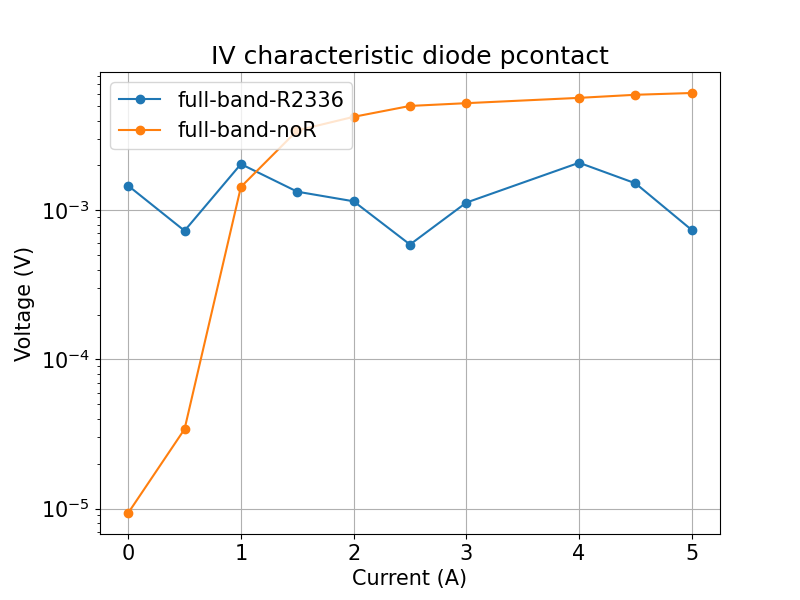

In [8]:
plt.close('all')
plt.figure(figsize=(8,6))
colors = ['r', 'b', 'g']
current = []
folder_list = [f"IV-R2336-{v:.2f}V" for v in bias]

for idx, (folder_name) in enumerate(folder_list):
    contact = "pcontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    # print("Reading file:", current_file)
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    current_np = current_all.to_numpy(dtype=float)
    t = time.to_numpy()
    # mean_current_svfilter = savgol_filter(current_np, window_length, polyorder)
    # tail_mean_micro = mean_current_svfilter[-10:].mean()
    tail_mean_micro = current_np[-10:].mean()
    # print(f"{leg_label}: media ultimi 10 punti = {tail_mean_micro:.3e} µA")
    current.append(abs(tail_mean_micro))

plt.semilogy(bias, current, 'o-', label=f"full-band-R2336")

current = []
folder_list = [f"IV-fb/IV-{v:.2f}V" for v in bias]
for idx, (folder_name) in enumerate(folder_list):
    contact = "pcontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    # print("Reading file:", current_file)
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    current_np = current_all.to_numpy(dtype=float)
    t = time.to_numpy()
    # mean_current_svfilter = savgol_filter(current_np, window_length, polyorder)
    # tail_mean_micro = mean_current_svfilter[-10:].mean()
    tail_mean_micro = current_np[-10:].mean()
    # print(f"{leg_label}: media ultimi 10 punti = {tail_mean_micro:.3e} µA")
    current.append(abs(tail_mean_micro))

plt.semilogy(bias, current, 'o-', label=f"full-band-noR")
plt.title(f'IV characteristic diode {contact}')
plt.ylabel('Voltage (V)')
plt.xlabel('Current (A)')
plt.grid(True)
plt.legend(loc='upper left')
plt.show()

# Current transient

## Import

In [14]:
# font size
rcParams['font.size'] = 15
# path
base_path = '/mnt/polmcad/MonteCarlo/DEMC/prove'
# folders to plot
# bias = np.linspace(0,5,11)
# bias = bias[bias != 3.5]
bias = 5
folder_list = [f"IV-R2336-{bias:.2f}V",f"IV-fb/IV-{bias:.2f}V"]
# folder_list = ["IV--5.00V"]

## Graph
### I(t)

<>:14: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:14: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/tmp/ipykernel_380598/1638516520.py:14: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.ylabel('Current $I_{D}$ ($\mu$A)')


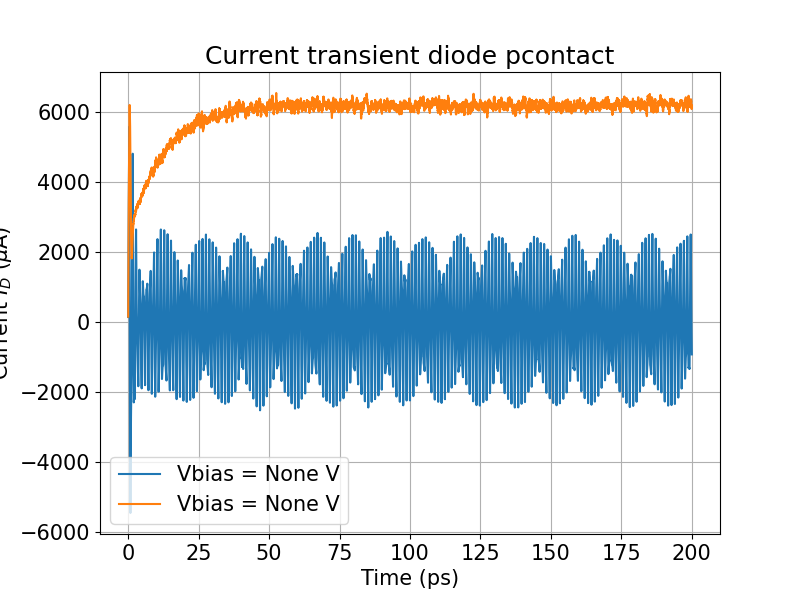

In [16]:
plt.close('all')
plt.figure(figsize=(8,6))
ax1 = plt.gca()
colors = ['r', 'b', 'g']
for idx, (folder_name) in enumerate(folder_list):
    contact = "pcontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()
    plt.plot(t*1e12, current_all/1e-6, label=f"Vbias = {vdc} V")

plt.xlabel('Time (ps)')
plt.ylabel('Current $I_{D}$ ($\mu$A)')
plt.title(f'Current transient diode {contact}')
plt.grid(True)
plt.legend(loc='lower left')
plt.show()

## SV filter

### Parameters

In [ ]:
# SV filter parameters
window_length = 501  # Deve essere un numero dispari
polyorder = 3       # Ordine del polinomio

## Graph
### I(t)

In [ ]:
plt.close('all')
plt.figure(figsize=(8,6))
ax1 = plt.gca()
colors = ['r', 'b', 'g']
for idx, (folder_name) in enumerate(folder_list):
    contact = "pcontact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()
    mean_current_svfilter = savgol_filter(current_all, window_length, polyorder)
    plt.plot(t*1e12, mean_current_svfilter/1e-6, label=f"Vbias = {vdc} ")

plt.xlabel('Time (ps)')
plt.ylabel('Current $I_{D}$ ($\mu$A)')
plt.title(f'Current transient diode {contact} - SV filter')
plt.grid(True)
# plt.legend(loc='lower left')
plt.show()

# Extra

In [ ]:
# valido solo per dt costante
from numpy.fft import fft, ifft, fftfreq




plt.figure(figsize=(8,6))

# colors = ['r', 'b', 'g']
# for idx, (folder_name, leg_label) in enumerate(zip(folder_list, label_list)):
#     contact = "pcontact"
#     vdc = extract_vdc_from_folder(folder_name)
#     current_file = f"{base_path}/{folder_name}/contact_current.csv"
#     current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
#     t = time.to_numpy()

#     mean_current_svfilter = savgol_filter(current_all, 51, 3)
#     t_gen = 1.5e-12
#     mask_t = (t>=t_gen) & (t<100e-12)
#     mean_current_svfilter = mean_current_svfilter[mask_t]
#     t = t[mask_t]
#     ramo_counter = 8
#     dt = 1e-15
    
#     current_fft = fft(mean_current_svfilter)
#     n = len(current_fft)
#     N = np.arange(n)
#     sampling_rate = 1/(dt*ramo_counter)
#     T = n/(sampling_rate)
#     f = fftfreq(n,d=dt*ramo_counter)

#     mask = f>= 0
#     f = f[mask]
#     H = current_fft[mask]

#     mag_db = 20*np.log10(np.abs(H))
    
#     plt.plot(t,mean_current_svfilter, label=f"Vbias = {vdc} V, {leg_label}")
#     

plt.figure(figsize=(8,6))

colors = ['r', 'b', 'g']
for idx, (folder_name, leg_label) in enumerate(zip(folder_list, label_list)):
    contact = "p-contact"
    vdc = extract_vdc_from_folder(folder_name)
    current_file = f"{base_path}/{folder_name}/contact_current.csv"
    print(current_file)
    current_all, voltage, time, std_dev = read_current_voltage(current_file, contact)
    t = time.to_numpy()

    mean_current_svfilter = savgol_filter(current_all, 51, 3)
    t_gen = 1.5e-12
    mask_t = (t>=t_gen) & (t<100e-12)
    mean_current_svfilter = mean_current_svfilter[mask_t]
    t = t[mask_t]
    ramo_counter = 8
    dt = 1e-15
    
    current_fft = fft(mean_current_svfilter)
    n = len(current_fft)
    N = np.arange(n)
    sampling_rate = 1/(dt*ramo_counter)
    T = n/(sampling_rate)
    f = fftfreq(n,d=dt*ramo_counter)

    mask = f>= 0
    f = f[mask]
    H = current_fft[mask]

    mag_db = 20*np.log10(np.abs(H))
    
    plt.plot(f*1e-9,mag_db-mag_db[1], label=f"Vbias = {vdc} V, {leg_label}") #normalized
    plt.xlim(1, 510)


plt.xlabel('Frequency, GHz')
plt.ylabel('Current (dB)')
plt.xscale('log')
plt.title(f'SPAD current fft')
plt.grid(True)
plt.legend()
plt.show()